# Do microRNAs in the cambium of Ginkgo trees change with tree age (20 → 200 → 600 years)?
**Riddhika D** · Plant Meristem Longevity project · clean re-analysis (v3)

**Data:** NCBI GEO **GSE119213**, small-RNA read counts from the vascular cambium (VC, the lateral meristem that makes wood) of *Ginkgo biloba* trees aged **20, 200 and 600 years**, **2 trees per age** (6 samples).

### Decided before looking at results
| | |
|---|---|
| **Main question** | Which miRNAs change steadily with tree age? |
| **Pre-specified miRNAs** | **miR156** (juvenility timer: expected to *fall* with age in most plants) and **miR165/166** (control HD-ZIP III meristem genes) |
| **Duplicates** | Many miRNA names (ath-, zma-, osa- …) are the *same* Ginkgo read mapped to several species' reference names. Rows with near-identical counts in all 6 samples are merged into one molecule |
| **Normalisation** | Counts per million (CPM), log2(CPM + 1); keep miRNAs with mean CPM ≥ 10 |
| **Test** | Linear trend of log2 CPM against log10(age) using all 6 samples; Benjamini–Hochberg FDR |
| **Honest limit** | n = 2 trees per age: results are *exploratory*, not proof |

Run: **Runtime → Run all** (about 1 minute). No Google Drive needed. Copy the **SEND THIS TO CLAUDE** box at the end.

In [1]:
import io, gzip, re, requests
import numpy as np, pandas as pd
from scipy import stats
REPORT = []
def note(s): print(s); REPORT.append(str(s))

URLS = ['https://ftp.ncbi.nlm.nih.gov/geo/series/GSE119nnn/GSE119213/suppl/GSE119213_miRNA.readcount.txt.gz',
        'https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE119213&format=file&file=GSE119213%5FmiRNA%2Ereadcount%2Etxt%2Egz']
raw = None
for u in URLS:
    try:
        r = requests.get(u, timeout=120); r.raise_for_status()
        raw = pd.read_csv(io.BytesIO(gzip.decompress(r.content)), sep='\t'); break
    except Exception as e: print('  failed', u[:70], str(e)[:80])
assert raw is not None, 'download failed - try again later'
note(f'GSE119213 miRNA table: {raw.shape[0]} miRNA names x {raw.shape[1] - 1} samples; columns: {list(raw.columns)}')

GSE119213 miRNA table: 632 miRNA names x 6 samples; columns: ['miRNA_name', 'VC20A.readcount', 'VC20B.readcount', 'VC200A.readcount', 'VC200B.readcount', 'VC600A.readcount', 'VC600B.readcount']


## 1. Samples and ages

In [2]:
cols = [c for c in raw.columns if c.endswith('.readcount')]
age = {c: int(re.search(r'VC(\d+)', c).group(1)) for c in cols}
note('samples: ' + ', '.join(f'{c.replace(".readcount", "")}={age[c]} y' for c in cols))
note('library sizes (total reads): ' + ', '.join(f'{c.replace(".readcount", "")}={int(raw[c].sum()):,}' for c in cols))
C = raw.set_index('miRNA_name')[cols].astype(float)

samples: VC20A=20 y, VC20B=20 y, VC200A=200 y, VC200B=200 y, VC600A=600 y, VC600B=600 y
library sizes (total reads): VC20A=1,481,283, VC20B=1,625,526, VC200A=1,184,091, VC200B=1,842,055, VC600A=1,641,695, VC600B=1,405,696


## 2. Merge duplicate names (same molecule, several species' names)
Two names are treated as one molecule when their counts agree within 2% (or within 2 reads) in **every** sample. The name with the highest total is kept; the others are listed.

In [3]:
# v3: only names from the SAME miRNA family (e.g. miR166) with >= 20 total reads can be merged;
# low-count rows (0-2 reads everywhere) are never merged, because they look identical by chance.
def same(a, b): return np.all(np.abs(a - b) <= np.maximum(2, 0.02 * np.maximum(a, b)))
def family(n):
    m = re.search(r'(miR\d+)', n, re.I); return m.group(1).lower() if m else n
order = C.sum(1).sort_values(ascending=False).index
groups, used = [], set()
V = C.values; idx = {n: i for i, n in enumerate(C.index)}; TOT = C.sum(1)
for n in order:
    if n in used: continue
    g = [n]; used.add(n)
    if TOT[n] >= 20:
        for m in order:
            if m not in used and TOT[m] >= 20 and family(m) == family(n) and same(V[idx[n]], V[idx[m]]):
                g.append(m); used.add(m)
    groups.append(g)
M = C.loc[[g[0] for g in groups]].copy()
ALIASES = {g[0]: g[1:] for g in groups}
merged = sum(len(g) - 1 for g in groups)
note(f'duplicate names merged: {merged}; unique molecules: {len(M)} (from {len(C)} names)')
for fam in ['miR156', 'miR165', 'miR166']:
    rows = [g for g in groups if family(g[0]) == fam.lower() and C.loc[g[0]].sum() > 0]
    note(f'  {fam}: {sum(len(g) for g in rows)} names -> {len(rows)} distinct molecules')

duplicate names merged: 31; unique molecules: 601 (from 632 names)
  miR156: 14 names -> 14 distinct molecules
  miR165: 2 names -> 1 distinct molecules
  miR166: 21 names -> 16 distinct molecules


## 3. Normalise and filter

In [4]:
CPM = M / M.sum(0) * 1e6
keep = CPM.mean(1) >= 10
L = np.log2(CPM[keep] + 1)
note(f'miRNAs with mean CPM >= 10: {keep.sum()} of {len(M)}')

miRNAs with mean CPM >= 10: 289 of 601


## 4. Age trend for every miRNA
log2 CPM ~ log10(age), 6 samples (df = 4). Positive slope = rises with age. Also reported: fold change 600 y vs 20 y.

In [5]:
x = np.log10([age[c] for c in cols])
res = []
for name, y in L.iterrows():
    s = stats.linregress(x, y.values)
    young = y[[c for c in cols if age[c] == min(age.values())]].mean()
    old = y[[c for c in cols if age[c] == max(age.values())]].mean()
    res.append(dict(miRNA=name, mean_CPM=CPM.loc[name].mean(), slope_per_log10age=s.slope, r=s.rvalue, p=s.pvalue,
                    log2FC_600_vs_20=old - young, n_aliases=len(ALIASES[name])))
R = pd.DataFrame(res)
p = R.p.values; o = np.argsort(p); q = p[o] * len(p) / np.arange(1, len(p) + 1)
q = np.minimum.accumulate(q[::-1])[::-1]; R.loc[R.index[o], 'FDR'] = np.minimum(q, 1)
R = R.sort_values('p'); R.to_csv('ginkgo_mirna_age_trend.csv', index=False)
for t in [0.05, 0.1]:
    s = R[R.FDR < t]
    note(f'FDR < {t}: {len(s)} miRNAs ({(s.slope_per_log10age > 0).sum()} rise, {(s.slope_per_log10age < 0).sum()} fall with age)')
note('top 10 by p-value:\n' + R.head(10)[['miRNA', 'mean_CPM', 'log2FC_600_vs_20', 'r', 'p', 'FDR', 'n_aliases']].round(4).to_string(index=False))

FDR < 0.05: 1 miRNAs (0 rise, 1 fall with age)
FDR < 0.1: 15 miRNAs (3 rise, 12 fall with age)
top 10 by p-value:
      miRNA  mean_CPM  log2FC_600_vs_20       r      p    FDR  n_aliases
 pab-miR397  561.4519           -6.2725 -0.9952 0.0000 0.0099          0
   novel_71  868.2734           -5.9044 -0.9795 0.0006 0.0682          0
  novel_306   81.6209           -3.8350 -0.9773 0.0008 0.0682          0
  novel_400 7876.0195           -5.5811 -0.9748 0.0009 0.0682          0
  novel_439  105.1937           -0.9415 -0.9716 0.0012 0.0694          0
smo-miR1083  165.0777           -0.9979 -0.9673 0.0016 0.0763          0
  novel_151   57.5637           -1.6924 -0.9629 0.0020 0.0827          0
  novel_139   99.1101           -3.2883 -0.9606 0.0023 0.0827          0
  novel_332   10.4718            2.8327  0.9583 0.0026 0.0827          0
  novel_101   87.5781            2.1105  0.9514 0.0035 0.0870          0


## 5. Pre-specified miRNAs: miR156 and miR165/166

In [6]:
pre = R[R.miRNA.str.contains('miR156|miR165|miR166', case=False)]
note('pre-specified families (each row = one distinct molecule):\n' +
     (pre[['miRNA', 'mean_CPM', 'log2FC_600_vs_20', 'r', 'p', 'FDR', 'n_aliases']].round(4).to_string(index=False) if len(pre) else 'none pass the CPM filter'))
m166 = pre[pre.miRNA.str.contains('miR166|miR165', case=False)]
up = int((m166.slope_per_log10age > 0).sum()); k = len(m166)
note(f'EXPLORATORY family direction: {up} of {k} distinct miR165/166 molecules rise with age '
     f'(sign test p = {stats.binomtest(up, k, 0.5).pvalue:.3f})' if k else 'no miR165/166 molecules')
for _, r_ in pre.iterrows():
    note(f'  {r_.miRNA} also named: {", ".join(ALIASES[r_.miRNA][:6]) or "-"}')

pre-specified families (each row = one distinct molecule):
         miRNA    mean_CPM  log2FC_600_vs_20       r      p    FDR  n_aliases
osa-miR166g-3p  21640.7466            0.5473  0.9007 0.0143 0.1238          3
mtr-miR156g-5p   2333.4739            2.1619  0.8082 0.0516 0.1798          0
osa-miR166d-5p     44.1754           -0.6373 -0.8049 0.0534 0.1799          0
   gma-miR166u 111431.5210            1.5243  0.8023 0.0548 0.1799          0
   osa-miR166m    400.3003            1.0176  0.7928 0.0599 0.1830          0
ath-miR166a-3p  89955.2892            1.7624  0.7896 0.0617 0.1830          2
   gma-miR166m    119.6351            1.7964  0.7776 0.0687 0.1908          0
   ppt-miR166j    174.9938            1.8005  0.7765 0.0693 0.1908          0
   mes-miR166i     52.8945            2.1448  0.7088 0.1148 0.2507          0
ath-miR165a-3p    151.1809            1.5211  0.7070 0.1162 0.2507          1
osa-miR166e-3p     10.3469            1.0784  0.6184 0.1907 0.3532          0
    h

## 6. Figure

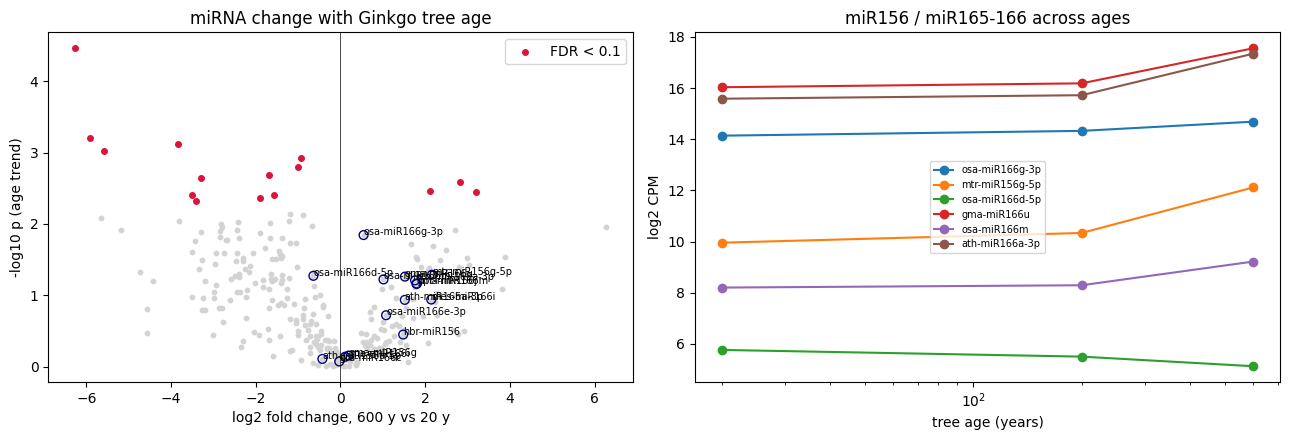

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(R.log2FC_600_vs_20, -np.log10(R.p), s=10, c='lightgray')
s = R[R.FDR < 0.1]; ax[0].scatter(s.log2FC_600_vs_20, -np.log10(s.p), s=16, c='crimson', label='FDR < 0.1')
for _, r_ in pre.iterrows():
    ax[0].scatter(r_.log2FC_600_vs_20, -np.log10(r_.p), s=40, facecolors='none', edgecolors='navy')
    ax[0].annotate(r_.miRNA, (r_.log2FC_600_vs_20, -np.log10(r_.p)), fontsize=7)
ax[0].axvline(0, color='k', lw=0.5); ax[0].set_xlabel('log2 fold change, 600 y vs 20 y'); ax[0].set_ylabel('-log10 p (age trend)')
ax[0].legend(); ax[0].set_title('miRNA change with Ginkgo tree age')
ages = sorted(set(age.values()))
for _, r_ in pre.head(6).iterrows():
    yy = [L.loc[r_.miRNA, [c for c in cols if age[c] == a]].mean() for a in ages]
    ax[1].plot(ages, yy, marker='o', label=r_.miRNA)
ax[1].set_xscale('log'); ax[1].set_xlabel('tree age (years)'); ax[1].set_ylabel('log2 CPM'); ax[1].legend(fontsize=7)
ax[1].set_title('miR156 / miR165-166 across ages')
plt.tight_layout(); plt.savefig('ginkgo_mirna_age.png', dpi=150); plt.show()

## How to read the result
- With **2 trees per age**, only large, consistent changes can pass FDR. A miRNA that passes is a **candidate**, not a proven age marker.
- **miR156 rising with age** would be unusual (in most plants it falls as plants mature) and would need checking in more trees.
- The merge step means each family's count reflects **distinct molecules**, not the number of species names.

In [8]:
print('=' * 70); print('SEND THIS TO CLAUDE'); print('=' * 70); print('\n'.join(REPORT)); print('=' * 70)

SEND THIS TO CLAUDE
GSE119213 miRNA table: 632 miRNA names x 6 samples; columns: ['miRNA_name', 'VC20A.readcount', 'VC20B.readcount', 'VC200A.readcount', 'VC200B.readcount', 'VC600A.readcount', 'VC600B.readcount']
samples: VC20A=20 y, VC20B=20 y, VC200A=200 y, VC200B=200 y, VC600A=600 y, VC600B=600 y
library sizes (total reads): VC20A=1,481,283, VC20B=1,625,526, VC200A=1,184,091, VC200B=1,842,055, VC600A=1,641,695, VC600B=1,405,696
duplicate names merged: 31; unique molecules: 601 (from 632 names)
  miR156: 14 names -> 14 distinct molecules
  miR165: 2 names -> 1 distinct molecules
  miR166: 21 names -> 16 distinct molecules
miRNAs with mean CPM >= 10: 289 of 601
FDR < 0.05: 1 miRNAs (0 rise, 1 fall with age)
FDR < 0.1: 15 miRNAs (3 rise, 12 fall with age)
top 10 by p-value:
      miRNA  mean_CPM  log2FC_600_vs_20       r      p    FDR  n_aliases
 pab-miR397  561.4519           -6.2725 -0.9952 0.0000 0.0099          0
   novel_71  868.2734           -5.9044 -0.9795 0.0006 0.0682       